In [15]:
!pip install PyMPDATA

In [16]:
import PyMPDATA
print(PyMPDATA.__file__)

/usr/local/lib/python3.13/dist-packages/PyMPDATA/__init__.py


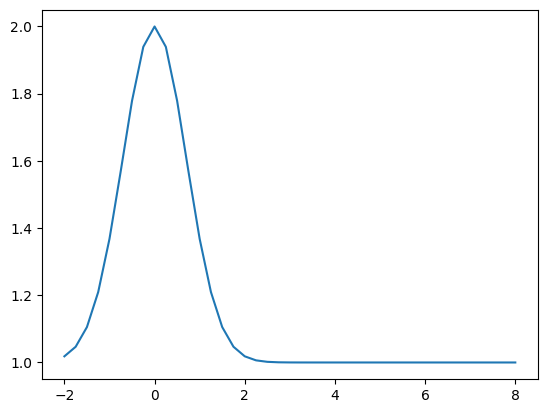

In [30]:
import numpy as np
import matplotlib.pyplot as plt

x=np.linspace(-2,8,41)
y=np.exp(-x*x)+1
plt.figure()
plt.plot(x,y)

In [31]:
from PyMPDATA import ScalarField, VectorField, Solver, boundary_conditions, Options , Stepper
common={
    'halo': (options:=Options(nonoscillatory=True)).n_halo,
    'boundary_conditions':(boundary_conditions.Periodic(), )
}
advector=VectorField(**common,data=(np.full(x.size+1,1/4),))
advectee=ScalarField(**common,data=y)
solver=Solver(advectee=advectee,advector=advector,stepper=Stepper(n_dims=1,options=options))
solver.advance(n_steps=100)

14835.29

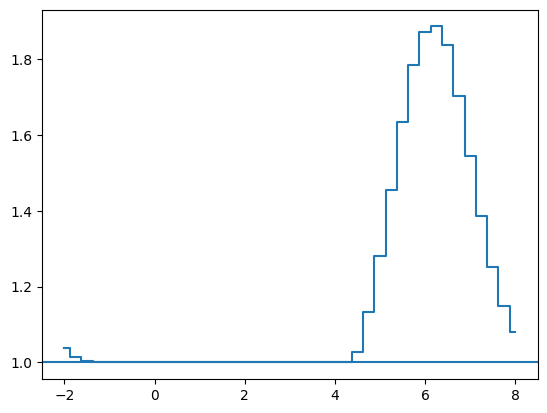

In [33]:
plt.step(x, solver.advectee.get(),where='mid')
plt.axhline(+1)